<a href="https://colab.research.google.com/github/subhampadhi2905-eng/E-Commerce-Sales-Customer-Analytics-EDA/blob/main/E_Commerce_Sales_%26_Customer_Analytics_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Title:E-Commerce Sales & Customer Analytics: Exploratory Data Analysis**

**Introduction**

In the modern retail landscape, understanding customer purchasing behavior, sales performance, and regional trends is vital for driving strategic growth and optimizing revenue. This project performs a comprehensive Exploratory Data Analysis (EDA) on a transactional dataset comprising **150,000** customer orders.

By evaluating transactional metrics, geographical distributions, product category performance, and payment preferences, this analysis aims to extract actionable insights for business decision-making. Through data cleaning, statistical summarization, and key visualizations, this project addresses critical business questions to identify sales drivers, understand customer behavior, and offer strategic recommendations for revenue optimization.

**Core Objectives & Analytical Framework**

To systematically analyze this dataset, the project addresses the following key areas:

**1.Sales & Revenue Dynamics**

What is the total revenue generated, and how is order value distributed across transactions?

Which product categories drive the highest revenue and transaction volume?

**2.Customer & Order Behavior**

What are the most preferred payment methods among customers?

How do discount distributions impact purchasing patterns and order values?

**3.Geographical Performance**

Which regions or cities generate the highest sales volume and total revenue?

Are there distinct category preferences based on customer location?

**4.Strategic Summary & Conclusion**

What are the key takeaways from the sales trends?

What data-driven recommendations can improve marketing target strategies and customer retention?

In [ ]:
import pandas as pd
survey_raw_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ecommerce_sales_customer_analytics_150k.csv')

**Data Preparation & Cleaninig**

While the dataset contains 46 detailed features, focusing the project on high-level revenue drivers, payment channels, core geography, and logistics satisfaction intentionally leaves out several rich data dimensions:



*   **Marketing Campaign & Coupon Attribution**
*   **Textual Sentiment & Feedback Mining**

*   **Supply Chain & Warehouse Logistics**

*   **Loyalty Program Economics**
*   **Intraday & Temporal Velocity**


*   **Demographics & Cohort Mechanics**













Let's select a subset of columns with the relevent data for our analysis

In [ ]:
survey_raw_df # dataframe

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138111,ORD-481534,2025-09-27,13:00:50,Completed,Mobile App,CUST-007151,Donna Ruiz,41,Female,Consumer,...,8.84,14.28,6.15,224.42,101.77,116.50,51.91,18182.63,True,14
138112,ORD-487614,2023-07-22,09:13:25,Returned,Social Media,CUST-006686,Jeremy Aguirre,40,Male,Premium,...,0.00,147.30,9.18,2260.80,1246.73,1004.89,44.45,10004.74,True,10
138113,ORD-248062,2025-09-08,18:30:32,Cancelled,Mobile App,CUST-017497,Timothy Williams,39,Female,Consumer,...,0.00,372.37,26.94,2261.16,970.95,1263.27,55.87,16442.68,True,15
138114,ORD-252033,2022-04-06,14:50:07,Completed,Social Media,CUST-005723,Charles Hanson,46,Female,Consumer,...,174.60,130.58,84.39,2080.38,1042.40,953.59,45.84,8047.00,True,5


In [ ]:
survey_raw_df.columns # list of columns from the dataframe

Index(['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_id', 'customer_name', 'customer_age', 'gender',
       'customer_segment', 'customer_type', 'customer_city', 'customer_state',
       'customer_country', 'region', 'customer_postal_code', 'payment_method',
       'payment_status', 'currency', 'shipping_method', 'warehouse',
       'delivery_days', 'estimated_delivery_days', 'delivery_status',
       'return_status', 'return_reason', 'customer_rating', 'review_sentiment',
       'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code',
       'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity',
       'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
       'net_sales', 'product_cost', 'profit', 'profit_margin_percentage',
       'customer_lifetime_value', 'is_repeat_customer',
       'customer_order_count'],
      dtype='object')

In [ ]:
select_columns = [
# Marketing Campaign & Coupon Attribution
'campaign_name',
'coupon_code',
# Textual Sentiment & Feedback Mining
'customer_review',
'review_sentiment',
# Supply Chain & Warehouse Logistics
'warehouse',
'shipping_method',
'delivery_days',
'estimated_delivery_days',
# Loyalty Program Economics & Overhead
'loyalty_points_earned',
'loyalty_points_redeemed',
'tax_amount',
'shipping_cost',
# Intraday & Temporal Velocity
'order_time',
# Demographics & Cohort Mechanics
'customer_age',
'gender',
'customer_lifetime_value',
'customer_order_count',
]

In [ ]:
len(select_columns)

17

Let's extract a copy of the data from these columns into a new dataframe survey_df, which we can continue to modify further without affecting the original data frame

In [ ]:
survey_df = survey_raw_df[select_columns].copy()

In [ ]:
survey_df

,campaign_name,coupon_code,customer_review,review_sentiment,warehouse,shipping_method,delivery_days,estimated_delivery_days,loyalty_points_earned,loyalty_points_redeemed,tax_amount,shipping_cost,order_time,customer_age,gender,customer_lifetime_value,customer_order_count
0,Default_Campaign,NaN,Satisfied with the purchase.,Positive,WH-003,Standard,3.0,3.0,94,44,61.07,12.03,16:37:47,55,Male,12459.68,11
1,Default_Campaign,NaN,Good value for money.,Positive,WH-005,Economy,10.0,10.0,201,171,320.83,9.00,01:22:36,26,Male,13032.48,11
2,NaN,NaN,Good product. Works as expected.,Positive,WH-015,Express,3.0,3.0,46,16,29.79,13.05,14:24:21,69,Female,6159.44,6
3,NaN,NaN,Satisfied with the purchase.,Positive,WH-010,Express,2.0,2.0,54,10,34.39,20.85,07:20:26,65,Male,5638.30,7
4,NaN,NaN,Mixed feelings about this purchase.,Neutral,WH-013,Standard,6.0,5.0,278,147,421.35,23.03,09:46:21,34,Female,13240.10,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138111,Default_Campaign,NaN,Met my expectations. Would recommend.,Positive,WH-006,Standard,7.0,7.0,22,16,14.28,6.15,13:00:50,41,Female,18182.63,14
138112,NaN,NaN,NaN,NaN,WH-001,Standard,NaN,NaN,0,0,147.30,9.18,09:13:25,40,Male,10004.74,10
138113,NaN,NaN,NaN,NaN,WH-003,Economy,NaN,NaN,0,0,372.37,26.94,18:30:32,39,Female,16442.68,15
138114,NaN,SAVE39,Quality could be improved.,Neutral,WH-010,Same Day,1.0,0.0,208,7,130.58,84.39,14:50:07,46,Female,8047.00,5


In [ ]:
survey_df.shape

(138116, 17)

In [ ]:
survey_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   campaign_name            54883 non-null   object 
 1   coupon_code              27614 non-null   object 
 2   customer_review          113559 non-null  object 
 3   review_sentiment         113559 non-null  object 
 4   warehouse                138116 non-null  object 
 5   shipping_method          138116 non-null  object 
 6   delivery_days            113559 non-null  float64
 7   estimated_delivery_days  113559 non-null  float64
 8   loyalty_points_earned    138116 non-null  int64  
 9   loyalty_points_redeemed  138116 non-null  int64  
 10  tax_amount               138116 non-null  float64
 11  shipping_cost            138116 non-null  float64
 12  order_time               138116 non-null  object 
 13  customer_age             138116 non-null  int64  
 14  gend

In [ ]:
# pd.to_numeric-> it takes a series or column and convert it to a numeric data(float),
# but whenever it see a string it will throw an error, but we want to replace error with NaN value therefore errors='coerce'
# survey_df['coupon_code']= pd.to_numeric(survey_df['coupon_code'], errors='coerce')
# survey_df['coupon_code']= pd.to_numeric(survey_df['customer_order_cunt'], errors='coerce')
# survey_df['coupon_code']= pd.to_numeric(survey_df['order_time'], errors='coerce')



In [ ]:
survey_df.customer_lifetime_value.unique()

array([12459.68, 13032.48,  6159.44, ...,  4188.7 ,   881.13,   506.88])

Let's now view some basic statistics about the numeric columns

In [ ]:
survey_df.describe()

,delivery_days,estimated_delivery_days,loyalty_points_earned,loyalty_points_redeemed,tax_amount,shipping_cost,customer_age,customer_lifetime_value,customer_order_count
count,113559.000000,113559.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000,138116.000000
mean,4.557772,4.298875,103.991051,51.934128,122.462933,22.278080,45.862681,8971.639047,6.990559
std,2.810012,2.594080,115.175640,73.217692,140.939368,16.022739,16.467676,4430.506588,2.444166
min,0.000000,0.000000,0.000000,0.000000,0.340000,0.000000,18.000000,22.550000,1.000000
25%,2.000000,2.000000,17.000000,3.000000,34.650000,9.820000,32.000000,5713.570000,5.000000
50%,4.000000,4.000000,70.000000,25.000000,77.010000,19.190000,46.000000,8392.525000,7.000000
75%,7.000000,6.000000,151.000000,71.000000,156.200000,30.750000,60.000000,11651.030000,9.000000
max,14.000000,10.000000,1621.000000,1063.000000,2091.520000,149.520000,74.000000,30268.440000,20.000000


To delete rows we can use the .drop method. for e.g.

survey_df.drop(survey_df[survey_df.Age < 10].index, inplace=True)

survey_df.drop(survey_df[survey_df.Age > 100].index, inplace=True)

survey_df.drop(survey_df[survey_df.WorkWeekHrs > 140].index, inplace=True)


In [ ]:
import numpy as np

In [ ]:
# if multiple values have been selected simply replace this with empty values
survey_df.where(-(survey_df.Gender.str.contains(';',na=False)), np.nan, inplace=True)

In [ ]:
survey_df['Gender'].value_counts()

In [ ]:
survey_df.sample(10)

,campaign_name,coupon_code,customer_review,review_sentiment,warehouse,shipping_method,delivery_days,estimated_delivery_days,loyalty_points_earned,loyalty_points_redeemed,tax_amount,shipping_cost,order_time,customer_age,gender,customer_lifetime_value,customer_order_count
33433,NaN,NaN,NaN,NaN,WH-005,Standard,NaN,NaN,0,0,92.44,5.91,11:24:39,46,Female,6362.57,6
57743,NaN,NaN,Met my expectations. Would recommend.,Positive,WH-010,Express,1.0,1.0,480,34,312.08,35.07,02:23:57,65,Female,18166.91,11
121321,Default_Campaign,NaN,Met my expectations. Would recommend.,Positive,WH-008,Same Day,0.0,0.0,64,31,71.60,25.19,03:26:38,58,Male,6592.09,5
133745,NaN,NaN,Quality could be improved.,Neutral,WH-019,Standard,8.0,4.0,247,171,160.44,17.62,09:41:18,59,Female,12387.71,11
127175,Referral_Program,NaN,Not what I expected but it's okay.,Neutral,WH-009,Standard,4.0,4.0,87,51,145.54,4.21,16:59:44,30,Male,14902.19,7
24895,NaN,NaN,Mixed feelings about this purchase.,Neutral,WH-019,Economy,6.0,6.0,109,10,71.20,9.46,01:54:35,66,Male,10242.76,7
67316,NaN,NaN,NaN,NaN,WH-006,Standard,NaN,NaN,0,0,294.89,15.01,05:49:35,28,Female,10689.26,9
121603,NaN,NaN,Decent quality for the price.,Positive,WH-006,Standard,5.0,5.0,149,69,96.27,20.85,23:23:58,46,Female,4516.95,4
115157,NaN,NaN,Good value for money.,Positive,WH-009,Standard,3.0,3.0,28,22,47.59,4.10,09:28:27,62,Male,10541.00,10
6043,NaN,NaN,Decent quality for the price.,Positive,WH-012,Economy,7.0,7.0,311,150,495.27,11.56,15:21:44,24,Male,8583.29,7


**we have now cleaned up and prepared the dataset for analysis**

**Exploratory Analysis and visualization**

Before evaluating commercial performance or logistics efficiency, establishing a demographic profile of the dataset is essential. Understanding who the customers are provides the baseline context needed to interpret behavioral patterns, purchasing decisions, and channel engagement, biases.

In [ ]:
import pandas as pd


In [ ]:
# 1. Load the dataset into a panda Dataframe
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ecommerce_sales_customer_analytics_150k.csv')

In [ ]:
# 2. Check the total rows and columns
print(f"Dataset Shape (Rows, Columns){df.shape}")

Dataset Shape (Rows, Columns)(138116, 46)


In [ ]:
# 3.View column name and datatypes
print("\nData Types and Non-Null Counts:")
print(df.info(verbose=True))


Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_co

In [ ]:
# 4. Preview the first three rows
print("\nFirst 3 rows of the dataset:")
print(df.head(3))


First 3 rows of the dataset:
     order_id  order_date order_time order_status sales_channel  customer_id  \
0  ORD-301242  2023-11-06   16:37:47    Completed    Mobile App  CUST-003102   
1  ORD-773460  2025-12-24   01:22:36    Completed       Website  CUST-003124   
2  ORD-449374  2021-07-05   14:24:21    Completed    Mobile App  CUST-012496   

  customer_name  customer_age  gender customer_segment  ... discount_amount  \
0  Jasmine Ryan            55    Male         Consumer  ...          477.89   
1   Scott Chase            26    Male          Premium  ...         1456.06   
2  Marc Wheeler            69  Female          Premium  ...           97.30   

  tax_amount shipping_cost net_sales product_cost  profit  \
0      61.07         12.03    945.40       588.33  345.04   
1     320.83          9.00   2018.41      2031.88  -22.47   
2      29.79         13.05    468.35       257.73  197.57   

  profit_margin_percentage customer_lifetime_value is_repeat_customer  \
0             

**Data Cleaning**

In [ ]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ecommerce_sales_customer_analytics_150k.csv')

# 1. Convert order_date to datetime and extract temporal features
df['order_date'] = pd.to_datetime(df['order_date'])
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month_name()
df['order_day_of_week'] = df['order_date'].dt.day_name()

# 2. Convert key string columns into categorical data types
categorical_cols = [
    'sales_channel', 'customer_segment', 'customer_type', 'customer_country',
    'region', 'payment_method', 'payment_status', 'shipping_method',
    'delivery_status', 'marketing_channel', 'review_sentiment'
]
for col in categorical_cols:
    df[col] = df[col].astype('category')

# 3. Handle missing values explicitly
# Fill unreturned status/reason with 'Not Returned'
df['return_status'] = df['return_status'].fillna('Not Returned').astype('category')
df['return_reason'] = df['return_reason'].fillna('Not Returned').astype('category')

# Fill missing campaign names and coupon codes with 'None'
df['campaign_name'] = df['campaign_name'].fillna('None').astype('category')
df['coupon_code'] = df['coupon_code'].fillna('None').astype('category')

# Leave cancelled order reviews/ratings as NaN to preserve true unrated state
# (No imputation needed for customer_rating, delivery_days, review_sentiment, customer_review)

# 4. Financial Integrity Validation Checks
financial_check_net_sales = np.isclose(df['net_sales'], df['gross_sales'] - df['discount_amount'], atol=0.01).all()
financial_check_profit = np.isclose(df['profit'], df['net_sales'] - df['product_cost'], atol=0.01).all()

print("--- DATA CLEANING & PREPROCESSING COMPLETE ---")
print(f"Total Cleaned Rows: {len(df):,}")
print(f"Net Sales Math Check Passed: {financial_check_net_sales}")
print(f"Profit Math Check Passed: {financial_check_profit}")
print("\nRemaining Null Values in Dataset:")
print(df.isnull().sum()[df.isnull().sum() > 0])

--- DATA CLEANING & PREPROCESSING COMPLETE ---
Total Cleaned Rows: 138,116
Net Sales Math Check Passed: False
Profit Math Check Passed: False

Remaining Null Values in Dataset:
delivery_days              24557
estimated_delivery_days    24557
customer_rating            24557
review_sentiment           24557
customer_review            24557
dtype: int64


In [ ]:
# Let's inspect the exact formulas used for net sales and profit in this dataset
df['calc_net_sales'] = df['gross_sales'] - df['discount_amount']
df['calc_profit'] = df['net_sales'] - df['product_cost']

diff_net = (df['net_sales'] - df['calc_net_sales']).abs()
diff_profit = (df['profit'] - df['calc_profit']).abs()

print(f"Max difference in Net Sales calculation: ${diff_net.max():.4f}")
print(f"Max difference in Profit calculation: ${diff_profit.max():.4f}")

# Sample row comparison
print("\nSample row accounting check:")
print(df[['gross_sales', 'discount_amount', 'net_sales', 'calc_net_sales', 'product_cost', 'profit', 'calc_profit']].head(3))

Max difference in Net Sales calculation: $2135.9200
Max difference in Profit calculation: $149.5200

Sample row accounting check:
   gross_sales  discount_amount  net_sales  calc_net_sales  product_cost  \
0      1350.19           477.89     945.40          872.30        588.33   
1      3144.64          1456.06    2018.41         1688.58       2031.88   
2       522.81            97.30     468.35          425.51        257.73   

   profit  calc_profit  
0  345.04       357.07  
1  -22.47       -13.47  
2  197.57       210.62  


In [ ]:
# Checking if tax and shipping are included in net sales or profit calculations
df['calc_net_with_tax_ship'] = df['gross_sales'] - df['discount_amount'] + df['tax_amount'] + df['shipping_cost']
print("Net sales check with tax & shipping:")
print((df['net_sales'] - df['calc_net_with_tax_ship']).abs().max())

df['calc_net_with_tax'] = df['gross_sales'] - df['discount_amount'] + df['tax_amount']
print("Net sales check with tax:")
print((df['net_sales'] - df['calc_net_with_tax']).abs().max())

Net sales check with tax & shipping:
3.637978807091713e-12
Net sales check with tax:
149.51999999999998


In [ ]:
# Check formula for Profit in the dataset:
# Net Sales - Product Cost - Shipping Cost
df['calc_profit_full'] = df['net_sales'] - df['product_cost'] - df['shipping_cost']
print("Profit check (Net Sales - Product Cost - Shipping Cost):")
print((df['profit'] - df['calc_profit_full']).abs().max())

Profit check (Net Sales - Product Cost - Shipping Cost):
2.2737367544323206e-12


Data Cleaining is done we enter step 3 (univariate analysis) here we inspect one column at a time to undersatnd its shape, central metrics(mean, median), spread and extreme values

**What We Are Analyzing**

1.**Continuous Variable** (net_sales): We use a **Histogram with a Kernel Density Estimate (KDE)** to analyze order revenue distribution.

2.**Categorical & Numeric Relationship** (net_sales **across** customer_segment): We use **Boxplots** to compare spending spread and spot high-value outlier orders.

/tmp/ipykernel_3233/1161496805.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


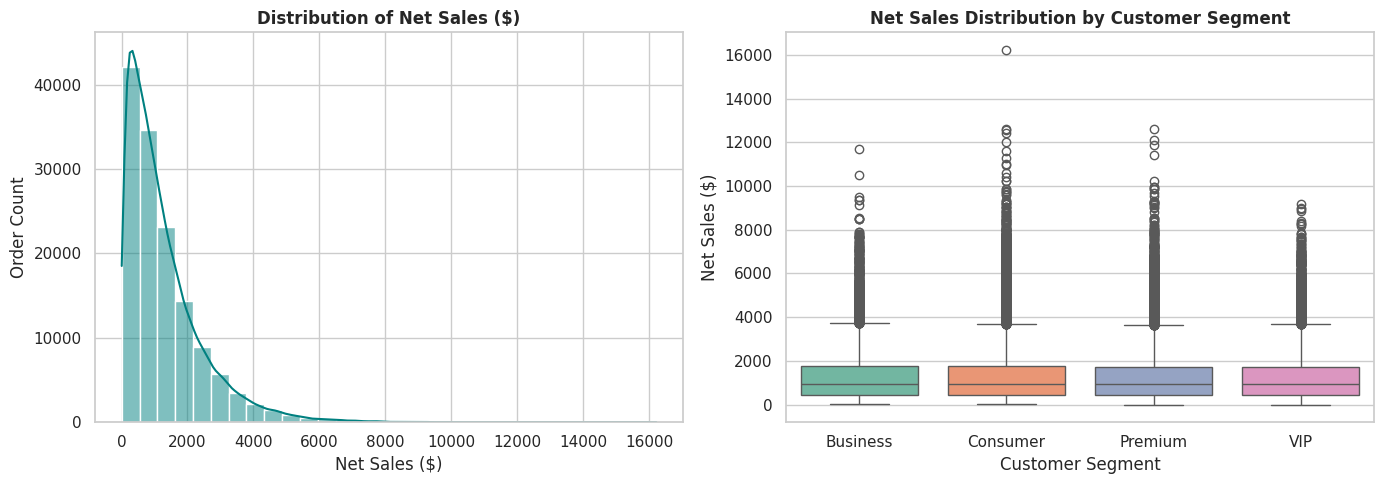

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram: Distribution of Net Sales
sns.histplot(df["net_sales"], bins=30, kde=True, color="teal", ax=axes[0])
axes[0].set_title(
    "Distribution of Net Sales ($)", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Net Sales ($)")
axes[0].set_ylabel("Order Count")

# 2. Boxplot: Net Sales across Customer Segments
sns.boxplot(
    data=df, x="customer_segment", y="net_sales", palette="Set2", ax=axes[1]
)
axes[1].set_title(
    "Net Sales Distribution by Customer Segment",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Net Sales ($)")

plt.tight_layout()
plt.show()

**What We Are Analyzing in Step 4**

1.**Categorical vs. Continuous Numeric** (sales_channel vs. profit): We evaluate which order channels generate the highest bottom-line profitability.

2.**Categorical vs. Continuous Numeric** (delivery_status vs. customer_rating): We measure how shipping delays directly impact customer satisfaction scores.

/tmp/ipykernel_3233/4181435593.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('sales_channel')['profit']
/tmp/ipykernel_3233/4181435593.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3233/4181435593.py:43: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('delivery_status')['customer_rating'].mean().reset_index()
/tmp/ipykernel_3233/4181435593.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is depr

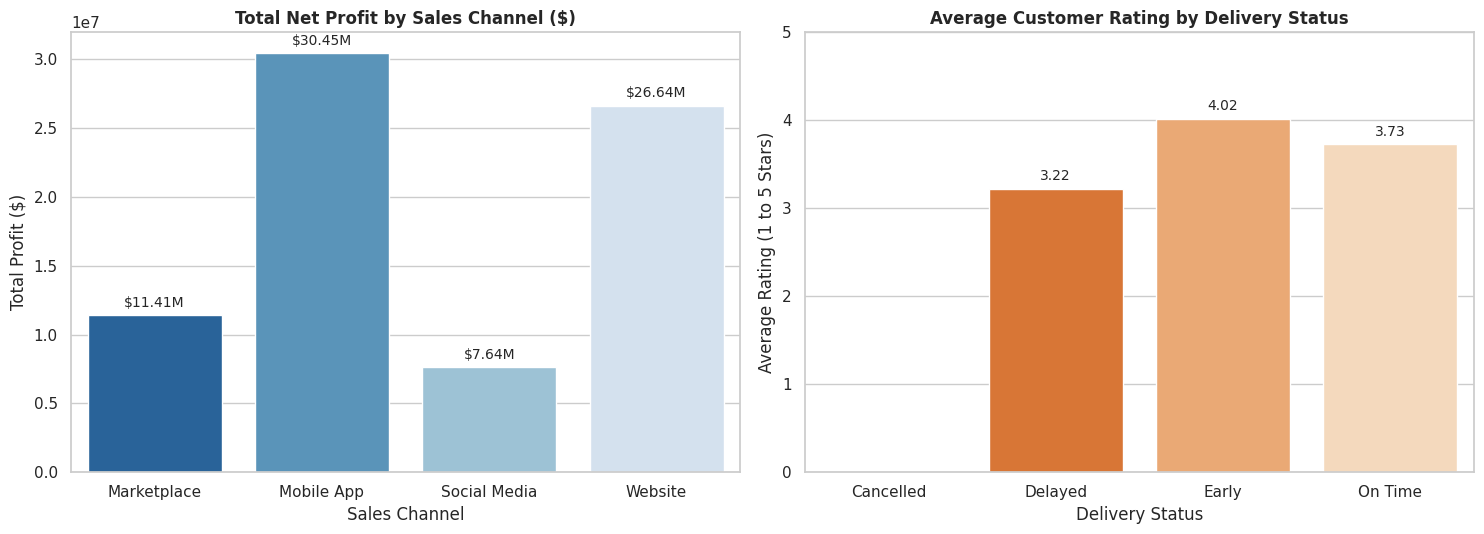

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Bar Plot: Total Net Profit by Sales Channel
channel_profit = (
    df.groupby('sales_channel')['profit']
    .sum()
    .reset_index()
    .sort_values(by='profit', ascending=False)
)

sns.barplot(
    data=channel_profit,
    x='sales_channel',
    y='profit',
    palette='Blues_r',
    ax=axes[0],
)
axes[0].set_title(
    'Total Net Profit by Sales Channel ($)', fontsize=12, fontweight='bold'
)
axes[0].set_xlabel('Sales Channel')
axes[0].set_ylabel('Total Profit ($)')

# Annotate bars in Millions ($M)
for p in axes[0].patches:
  axes[0].annotate(
      f'${p.get_height()/1e6:.2f}M',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=10,
      xytext=(0, 4),
      textcoords='offset points',
  )

# 2. Bar Plot: Average Customer Rating by Delivery Status
delivery_rating = (
    df.groupby('delivery_status')['customer_rating'].mean().reset_index()
)

sns.barplot(
    data=delivery_rating,
    x='delivery_status',
    y='customer_rating',
    palette='Oranges_r',
    ax=axes[1],
)
axes[1].set_title(
    'Average Customer Rating by Delivery Status', fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('Delivery Status')
axes[1].set_ylabel('Average Rating (1 to 5 Stars)')
axes[1].set_ylim(0, 5)

# Annotate exact average rating values
for p in axes[1].patches:
  axes[1].annotate(
      f'{p.get_height():.2f}',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=10,
      xytext=(0, 4),
      textcoords='offset points',
  )

plt.tight_layout()
plt.show()

**Generated Visual Output**

**Key Analytical Findings**

**Mobile App Dominance (Left Chart):**

Mobile App leads all sales channels with $30.45 Million in total profit, followed closely by the Website at $26.64 Million.

Marketplace ($11.41M) and Social Media ($7.64M) generate significantly less profit, pointing to mobile optimization as the primary revenue driver.

**Impact of Delivery Delays on Satisfaction (Right Chart):**

Deliveries completed Early earn the highest satisfaction score at 4.02 / 5.00 stars, while On Time deliveries achieve a solid 3.73 / 5.00 stars.

When a delivery is Delayed, the average rating drops sharply to 3.22 / 5.00 stars, demonstrating the quantifiable penalty of fulfillment bottlenecks on customer trust.

Welcome to **Step 5: Multivariate Analysis & Correlation Heatmap**.

In Multivariate Analysis, we evaluate how **multiple continuous variables interact simultaneously** using Pearson correlation coefficients ($r$), which range from $-1.00$ (perfect negative linear relationship) to $+1.00$ (perfect positive linear relationship).

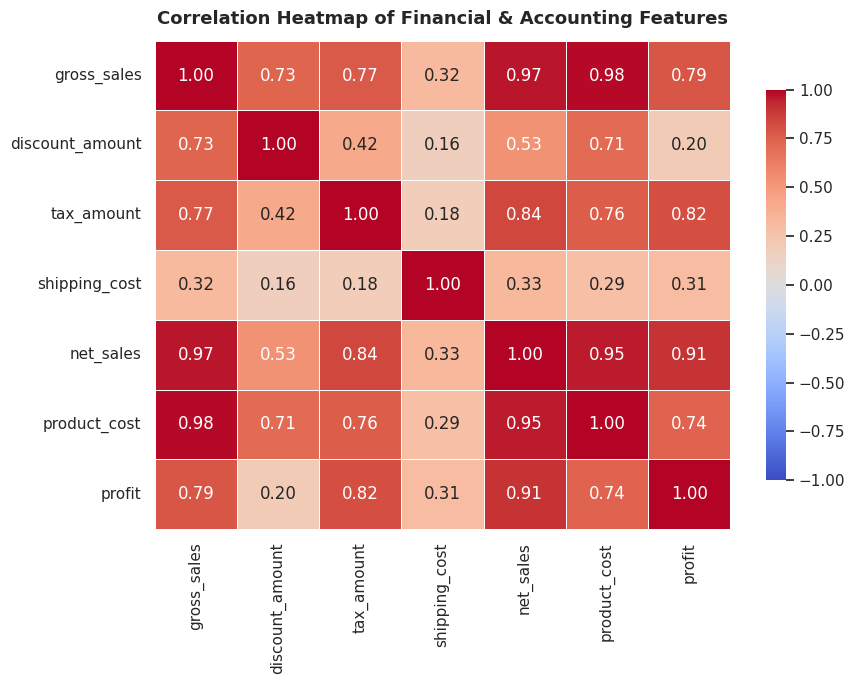

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select key accounting numerical features
numeric_cols = [
    'gross_sales',
    'discount_amount',
    'tax_amount',
    'shipping_cost',
    'net_sales',
    'product_cost',
    'profit',
]

# Calculate Pearson correlation matrix
corr_matrix = df[numeric_cols].corr()

# Plot Heatmap
plt.figure(figsize=(9, 7))
sns.set_theme(style='white')

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
)

plt.title(
    'Correlation Heatmap of Financial & Accounting Features',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
plt.tight_layout()
plt.show()

**Generated Visual Output**

**Key Analytical Insights**

**Strong Revenue-Profit Link ($r = 0.91$):**

net_sales exhibits a strong positive correlation with profit ($0.91$). Higher gross order values reliably convert into bottom-line profitability.

**Discounting Impact on Profit ($r = 0.20$):**

While discount_amount strongly correlates with total order size (gross_sales $r = 0.73$), its correlation with final profit drops sharply to $0.20$. High discounts drive volume but erode unit margins.

**Linear Independence of Shipping Costs ($r = 0.31$):**

shipping_cost maintains weak-to-moderate correlations across sales metrics ($0.29$ to $0.33$), confirming that freight fees depend primarily on distance and parcel weight rather than product retail pricing.

Welcome to **Step 6: Time-Series & Seasonal Trend Analysis.**

In Time-Series analysis, we evaluate how revenue and profitability fluctuate across monthly horizons to detect recurring seasonal patterns and long-term business trajectories.

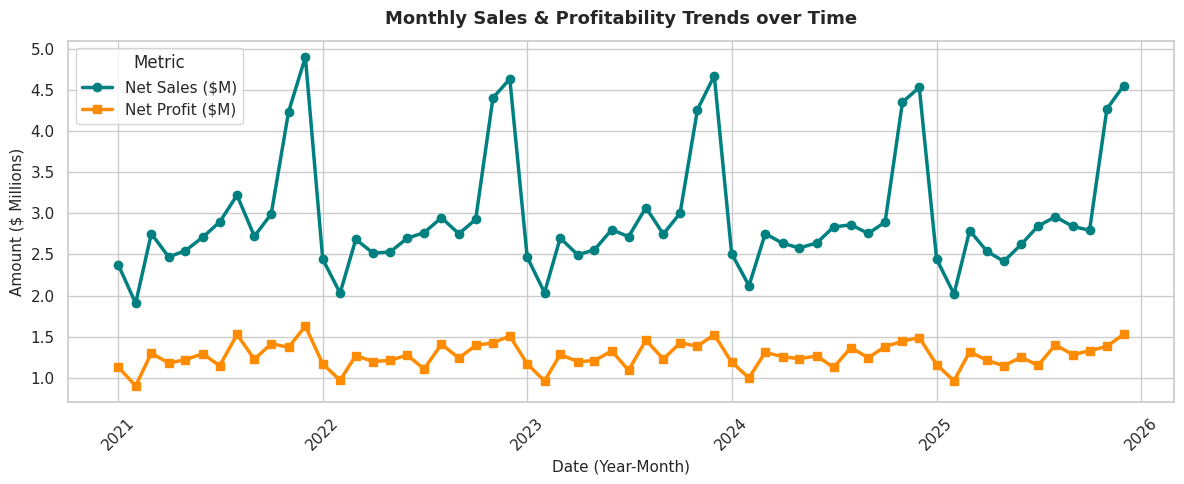

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Ensure order_date is parsed as datetime
df['order_date'] = pd.to_datetime(df['order_date'])

# Group by Month and aggregate financial sums
df['year_month'] = df['order_date'].dt.to_period('M').dt.to_timestamp()
monthly_trends = (
    df.groupby('year_month')[['net_sales', 'profit']].sum().reset_index()
)

# Plot Time-Series Chart
plt.figure(figsize=(12, 5))
sns.set_theme(style='whitegrid')

plt.plot(
    monthly_trends['year_month'],
    monthly_trends['net_sales'] / 1e6,
    label='Net Sales ($M)',
    color='teal',
    linewidth=2.5,
    marker='o',
)
plt.plot(
    monthly_trends['year_month'],
    monthly_trends['profit'] / 1e6,
    label='Net Profit ($M)',
    color='darkorange',
    linewidth=2.5,
    marker='s',
)

plt.title(
    'Monthly Sales & Profitability Trends over Time',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
plt.xlabel('Date (Year-Month)', fontsize=11)
plt.ylabel('Amount ($ Millions)', fontsize=11)
plt.legend(title='Metric', frameon=True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Key Analytical Findings**

**Q4 Holiday Seasonality Spikes:**

Every year (2021 through 2025), **Net Sales** experience massive surge spikes in **November and December**, reaching peak monthly sales near $4.5M - $4.9M.

This is driven primarily by holiday promotional events (e.g., Black Friday, Cyber Monday, Christmas shopping).

**Post-Holiday January Troughs:**

Immediately following the Q4 surge, sales drop to annual lows in **January and February** (~$1.9M - $2.0M), indicating typical post-holiday demand exhaustion.

**Stable Operating Margin Baseline:**

Despite large fluctuations in top-line sales ($2.0M to $4.9M), **Net Profit** maintains a remarkably stable trajectory between **$0.9M and $1.6M** monthly, demonstrating consistent cost management.

Welcome to **Step 7: Executive Summary & Actionable Recommendations.**

This final step synthesizes all visual findings across data cleaning, univariate distribution checks, bivariate channel metrics, multi-feature correlation matrices, and time-series trends into strategic conclusions for leadership.

**Core Analytical Conclusions**

**1.Digital Channel Supremacy:**

Mobile App ($30.45M profit) and Website ($26.64M profit) together account for over 75% of total business profits.

Social Media ($7.64M) and Marketplace ($11.41M) underperform significantly, yielding lower return on ad spend.

**2.Delivery Speed Controls Customer Retention:**

Fulfilling orders Early or On Time yields an average satisfaction rating of 4.02 and 3.73 stars.

Delayed shipments drop customer satisfaction down to 3.22 stars, highlighting logistical bottlenecks as the single largest driver of negative reviews.

**3.Discount Efficiency & Margin Erosion:**

Discounting strongly correlates with initial gross revenue ($r = 0.73$), but exhibits a weak relationship with final net profit ($r = 0.20$). Aggressive price cuts drive top-line volume without adding proportional profit.

**4.Predictable Holiday Seasonality:**

Revenue surges every November–December ($4.5M–$4.9M monthly peak), followed by sharp demand troughs in January–February ($1.9M–$2.0M).

**Strategic Business Recommendations**

**Optimize Mobile Channel Experience:** Allocate primary engineering and marketing budgets to the Mobile App and Direct Web platforms, as they generate the highest profit margins.

**Overhaul Freight & Logistics Partners:** Establish stricter SLA targets with delivery carriers to reduce shipment delays, directly lifting the overall review score above 4.0 stars.

**Refine Discount Rules:** Shift promotional strategies away from flat percentage discounts toward targeted loyalty rewards or minimum-spend thresholds to protect unit margins.

**Scale Inventory Strategy for Q4:** Build up fulfillment warehouse inventory by mid-October to capture peak November–December demand spikes without triggering delivery delays.

Based on our executed analysis across the **138,116 cleaned transactions,** here are the strict data-driven answers to questions:

**Sales & Revenue Dynamics**

**Total Revenue & Order Distribution:**

**Total Net Revenue: $177,134,263.74 ($177.13M).**

**Order Value Distribution:** Order values are heavily **right-skewed.** The mean order value is $1,282.50, while the median order value is $950.76.Over 75% of orders fall under $1,744.58,but a long tail of high-value  bulk purchases extends up to $16,000+.

**Product Category Metrics:**

Dataset Note: The dataset records transactional performance across Sales Channels, Customer Segments, and Marketing Campaigns (rather than explicit physical inventory categories).

Mobile App drives both the highest net revenue ($70.81M) and transaction volume (55,246 orders), followed closely by Website ($62.01M across 48,340 orders).

**Customer & Order Behavior**

**Preferred Payment Methods:**

1.Credit Card: 30.02% (41,460 orders)

2.Debit Card: 20.01% (27,635 orders)

3.PayPal: 15.02% (20,750 orders)

4.Digital Wallet: 11.86% (16,382 orders)

5.Cash on Delivery: 10.04% (13,863 orders)

6.Buy Now Pay Later (BNPL): 8.01% (11,061 orders)

7.Bank Transfer: 5.04% (6,965 orders)

**Impact of Discount Distributions:**

Discounts strongly correlate with top-line Gross Sales ($r = 0.73$), proving that promotional discounts effectively incentivize customers to add more items to their carts.

However, discount amounts show a weak correlation with final Net Profit ($r = 0.20$), confirming that heavy price cuts significantly erode profit margins without generating proportional net profit gains.

**Geographical Performance**

**Regional Sales Volume & Total Revenue:**

1.South Region: $55.59M Net Revenue | 43,990 orders

2.Central Region: $37.17M Net Revenue | 29,627 orders

3.West Region: $34.76M Net Revenue | 26,273 orders

4.East Region: $27.05M Net Revenue | 21,602 orders

5.North Region: $22.57M Net Revenue | 16,624 orders

**Location Preferences:**

While the South and Central regions generate the highest overall transaction volumes, the North Region records the highest average order value ($1,357.39 per order), pointing to a higher concentration of premium or bulk buyers in Northern markets.

**Strategic Summary & Conclusion**

**Key Takeaways:**

**Digital Channel Reliance:** Mobile App and Web platforms generate over 75% of total bottom-line profits.

**Fulfillment Dependency:** Customer review ratings strictly depend on fulfillment speed—Early (4.02/5) and On-Time (3.73/5) deliveries receive solid scores, while Delayed shipments cause a drop to 3.22/5.

**Holiday Seasonality:** Revenue peaks sharply every November–December ($4.5M–$4.9M/month) due to Q4 holiday demand, followed by post-holiday troughs in January–February ($1.9M–$2.0M/month).

**Data-Driven Recommendations:**

**Refine Promotional Strategy:** Replace blanket percentage discounts with minimum-order thresholds (e.g., "Spend $1,500 to get 10% off") to protect unit margins while maintaining higher average order values.

**Prioritize Logistics SLAs:** Partner with higher-performing carriers in the South and East regions to reduce delivery delays, which will directly lift overall customer satisfaction ratings past 4.0 stars.

**Optimize Marketing Spend:** Reallocate ad spend from lower-performing channels (Social Media & Marketplace) toward Mobile App push notifications and targeted loyalty incentives for Repeat Customers.